# Feature Scaling - Standardization

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("Social_Network_Ads.csv")

In [7]:
# df=df.iloc[:,2:]
df.sample(5)


,Age,EstimatedSalary,Purchased
263,35,72000,0
37,30,49000,0
160,32,100000,1
347,54,108000,1
169,29,47000,0


# Train test split

In [9]:
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test=train_test_split(df.drop('Purchased',axis=1),
                                               df['Purchased'],
                                               test_size=0.3,
                                               random_state=0)
X_train.shape,X_test.shape


((280, 2), (120, 2))

# StandardScaler

In [10]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()

# fit the scaler to the train set, it will leran the parameters
scaler.fit(X_train)
# transform train and test sets...

X_train_scaled=scaler.transform(X_train)
X_test_scaled=scaler.transform(X_test)


In [ ]:
scaler.mean_

#  mean of (age , salary )

array([3.78642857e+01, 6.98071429e+04])

In [22]:
X_train_scaled=pd.DataFrame(X_train_scaled,columns=X_train.columns)
X_test_scaled=pd.DataFrame(X_test_scaled, columns=X_test.columns)

In [18]:

#  numphy array 
X_train
# X_train_scaled 



,Age,EstimatedSalary
92,26,15000
223,60,102000
234,38,112000
232,40,107000
377,42,53000
...,...,...
323,48,30000
192,29,43000
117,36,52000
47,27,54000


In [21]:
# original data ka 
np.round(X_train.describe(),1)

,Age,EstimatedSalary
count,280.0,280.0
mean,37.9,69807.1
std,10.2,34641.2
min,18.0,15000.0
25%,30.0,43000.0
50%,37.0,70500.0
75%,46.0,88000.0
max,60.0,150000.0


In [23]:
# trained data(mean=0,std=1)
np.round(X_train_scaled.describe(),1)


,Age,EstimatedSalary
count,280.0,280.0
mean,0.0,0.0
std,1.0,1.0
min,-1.9,-1.6
25%,-0.8,-0.8
50%,-0.1,0.0
75%,0.8,0.5
max,2.2,2.3


# Effect of scalling

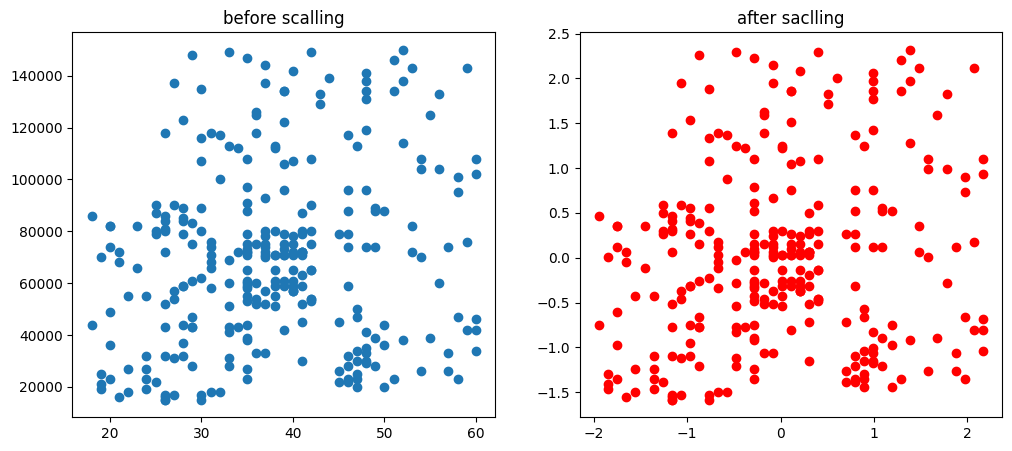

In [ ]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))
ax1.scatter(X_train['Age'],X_train['EstimatedSalary'])
ax1.set_title("before scalling")
ax2.scatter(x=X_train_scaled["Age"],y=X_train_scaled['EstimatedSalary'],color='red')
ax2.set_title("after saclling")
plt.show()
#  data center ho gya hai (mean=0 se );

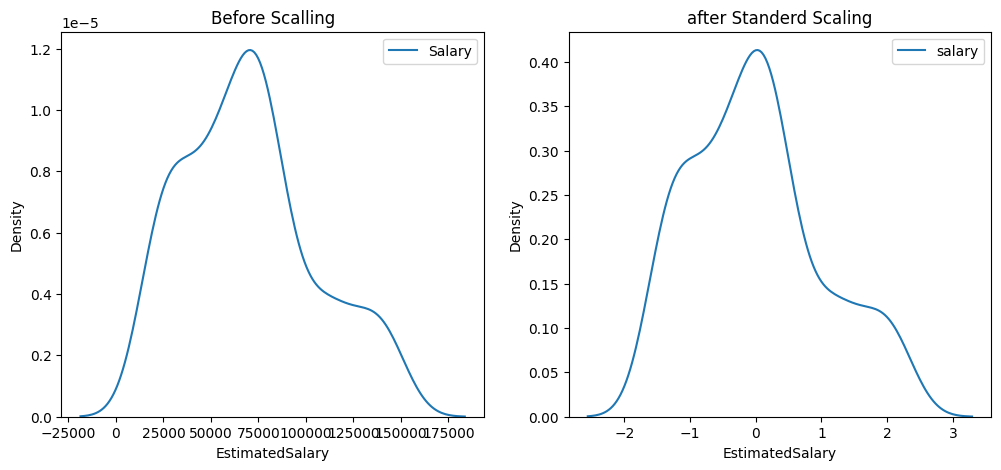

In [33]:
fig,(ax1,ax2)=plt.subplots(ncols=2,figsize=(12,5))
# before scalling
ax1.set_title("Before Scalling")
# sns.kdeplot(X_train['Age'],ax=ax1,label='Age')
sns.kdeplot(X_train['EstimatedSalary'],ax=ax1,label="Salary")
ax1.legend()

#after scaling
ax2.set_title("after Standerd Scaling")
# sns.kdeplot(X_train_scaled['Age'],ax=ax2,label='Age')
sns.kdeplot(X_train_scaled['EstimatedSalary'],ax=ax2,label='salary')
ax2.legend()

plt.show()

# why scaling is important ?


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LogisticRegression

# Models
lr = LogisticRegression()
lr_scaled = LogisticRegression()

# Train on normal data
lr.fit(X_train, Y_train)

# Train on scaled data
lr_scaled.fit(X_train_scaled, Y_train)  

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [ ]:
# Without scaling
y_pred = lr.predict(X_test)

# With scaling
y_pred_scaled = lr_scaled.predict(X_test_scaled)

In [54]:
from sklearn.metrics import accuracy_score

In [56]:
print('actual', accuracy_score(Y_test,y_pred))
print("scaled",accuracy_score(Y_test,y_pred_scaled))

actual 0.875
scaled 0.8666666666666667


In [57]:
from sklearn.tree import DecisionTreeClassifier

In [58]:
dt=DecisionTreeClassifier()
dt_scaled=DecisionTreeClassifier()

In [59]:
dt.fit(X_train,Y_train)
dt_scaled.fit(X_train_scaled,Y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [60]:
y_pred=dt.predict(X_test)
y_pred_scaled=dt_scaled.predict(X_test_scaled)

In [61]:
print("actual",accuracy_score(Y_test,y_pred))
print("scaled",accuracy_score(Y_test,y_pred_scaled))

actual 0.875
scaled 0.8666666666666667


In [62]:
df.describe()

,Age,EstimatedSalary,Purchased
count,400.000000,400.000000,400.000000
mean,37.655000,69742.500000,0.357500
std,10.482877,34096.960282,0.479864
min,18.000000,15000.000000,0.000000
25%,29.750000,43000.000000,0.000000
50%,37.000000,70000.000000,0.000000
75%,46.000000,88000.000000,1.000000
max,60.000000,150000.000000,1.000000


# effect of outlier

In [66]:
import pandas as pd

new_data = pd.DataFrame({
    "Age": [5, 90, 95],
    "EstimatedSalary": [1000, 250000, 350000],
    "Purchased": [0, 1, 1]
})

df = pd.concat([df, new_data], ignore_index=True)

In [67]:
df

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0
...,...,...,...
398,36,33000,0
399,49,36000,1
400,5,1000,0
401,90,250000,1


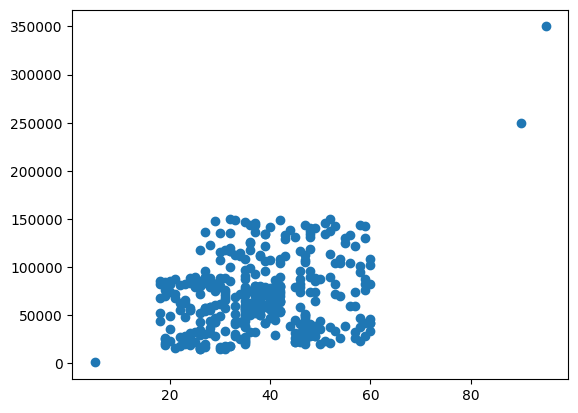

In [68]:
plt.scatter(df['Age'],df['EstimatedSalary'])

In [70]:
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test=train_test_split(df.drop('Purchased',axis=1),
                                               df['Purchased'],
                                               test_size=0.3,
                                               random_state=0)
X_train.shape,X_test.shape


((282, 2), (121, 2))

In [71]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()

# fit the scaler to the train set, it will leran the parameters
scaler.fit(X_train)
# transform train and test sets...

X_train_scaled=scaler.transform(X_train)
X_test_scaled=scaler.transform(X_test)


In [72]:
X_train_scaled=pd.DataFrame(X_train_scaled,columns=X_train.columns)
X_test_scaled=pd.DataFrame(X_test_scaled, columns=X_test.columns)

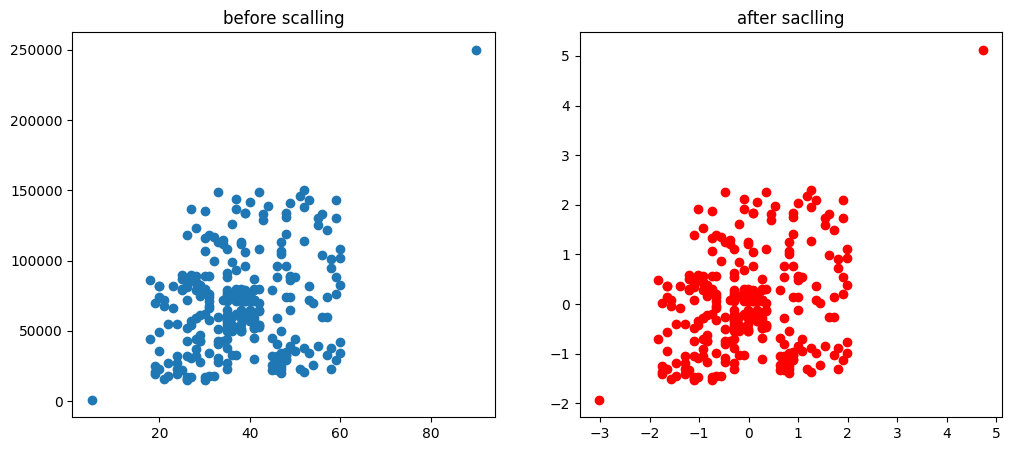

In [73]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))
ax1.scatter(X_train['Age'],X_train['EstimatedSalary'])
ax1.set_title("before scalling")
ax2.scatter(x=X_train_scaled["Age"],y=X_train_scaled['EstimatedSalary'],color='red')
ax2.set_title("after saclling")
plt.show()
#  data center ho gya hai (mean=0 se );